In [4]:
# Import libraries
import cv2
import numpy as np
import matplotlib.pyplot as plt

Text(0.5, 1.0, 'Face')

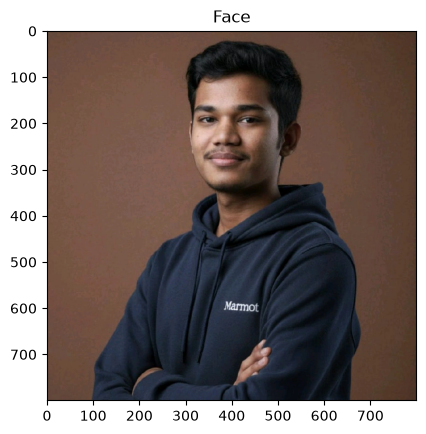

In [5]:
# Load the Face Image
faceImage = cv2.imread('./imgs/profile.png')
plt.imshow(faceImage[:,:,::-1]);plt.title("Face")


In [6]:
faceImage.shape

(800, 800, 3)

In [7]:
#resized_faceImage.shape
faceImage.shape

(800, 800, 3)

Text(0.5, 1.0, 'glassPNG')

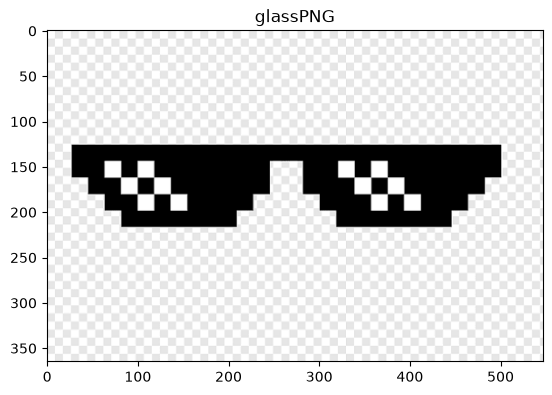

In [8]:
# Load the Sunglass image with Alpha channel
# (http://pluspng.com/sunglass-png-1104.html)
glassPNG = cv2.imread('./imgs/image.png',-1)
plt.imshow(glassPNG[:,:,::-1]);plt.title("glassPNG")

In [9]:
x, y, w, h = 297, 140, 210, 110
glassPNG = cv2.resize(glassPNG, (w, h), interpolation=cv2.INTER_AREA)
print("Sunglasses dimensions:", glassPNG.shape)

Sunglasses dimensions: (110, 210, 3)


In [10]:
glassBGR = glassPNG[:, :, :3]

if glassPNG.ndim == 3 and glassPNG.shape[2] == 4:
    alpha = glassPNG[:, :, 3].astype(np.float32) / 255.0
else:
    gray = cv2.cvtColor(glassBGR, cv2.COLOR_BGR2GRAY)
    # Soft transparency for white/near-white backgrounds
    alpha = (255 - gray).astype(np.float32) / 255.0
    alpha = np.clip(alpha, 0, 1)

alpha = cv2.GaussianBlur(alpha, (3, 3), 0)


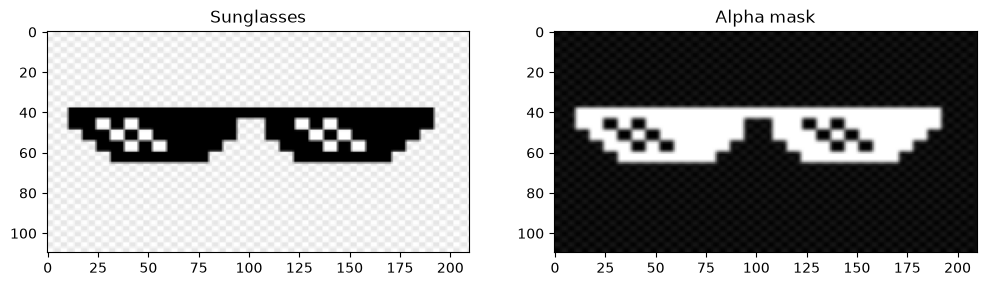

In [11]:
plt.figure(figsize=[12, 5])
plt.subplot(121); plt.imshow(cv2.cvtColor(glassBGR, cv2.COLOR_BGR2RGB)); plt.title("Sunglasses")
plt.subplot(122); plt.imshow(alpha, cmap="gray", vmin=0, vmax=1); plt.title("Alpha mask")
plt.show()

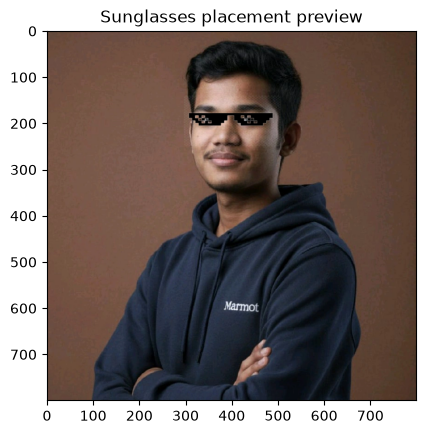

In [12]:
# Quick preview: place sunglasses at (x, y) with size (w, h).
faceWithGlassesNaive = faceImage.copy()
H, W = faceImage.shape[:2]
x0, y0 = max(0, x), max(0, y)
x1, y1 = min(W, x + w), min(H, y + h)

if x0 < x1 and y0 < y1:
    # Crop overlay/mask if it extends beyond image boundaries
    gx0, gy0 = x0 - x, y0 - y
    overlay = glassBGR[gy0:gy0 + (y1-y0), gx0:gx0 + (x1-x0)]
    a = alpha[gy0:gy0 + (y1-y0), gx0:gx0 + (x1-x0), None]
    roi = faceWithGlassesNaive[y0:y1, x0:x1].astype(np.float32)
    faceWithGlassesNaive[y0:y1, x0:x1] = (a * overlay + (1-a) * roi).clip(0,255).astype(np.uint8)

plt.imshow(cv2.cvtColor(faceWithGlassesNaive, cv2.COLOR_BGR2RGB))
plt.title("Sunglasses placement preview")
plt.show()


In [13]:
# Resize sunglasses to match the eye ROI dimensions
eyeROI = faceImage[140:250, 297:507]

glassBGR = cv2.resize(
    glassBGR,
    (eyeROI.shape[1], eyeROI.shape[0]),
    interpolation=cv2.INTER_AREA
)

alpha = cv2.resize(
    alpha,
    (eyeROI.shape[1], eyeROI.shape[0]),
    interpolation=cv2.INTER_AREA
)

# Create a 3-channel mask
glassMask = cv2.merge((alpha, alpha, alpha))

# Convert mask to float32
glassMask = glassMask.astype(np.float32)

# Convert images to float32
eyeROI = eyeROI.astype(np.float32)
glassBGR = glassBGR.astype(np.float32)

# Apply mask to eye region
maskedEye = cv2.multiply(eyeROI, 1 - glassMask)

# Apply mask to sunglasses
maskedGlass = cv2.multiply(glassBGR, glassMask)

# Combine both images
eyeRoiFinal = cv2.add(maskedEye, maskedGlass)

# Create final augmented image
faceWithGlassesArithmetic = faceImage.copy()

faceWithGlassesArithmetic[140:250, 297:507] = np.clip(
    eyeRoiFinal, 0, 255
).astype(np.uint8)

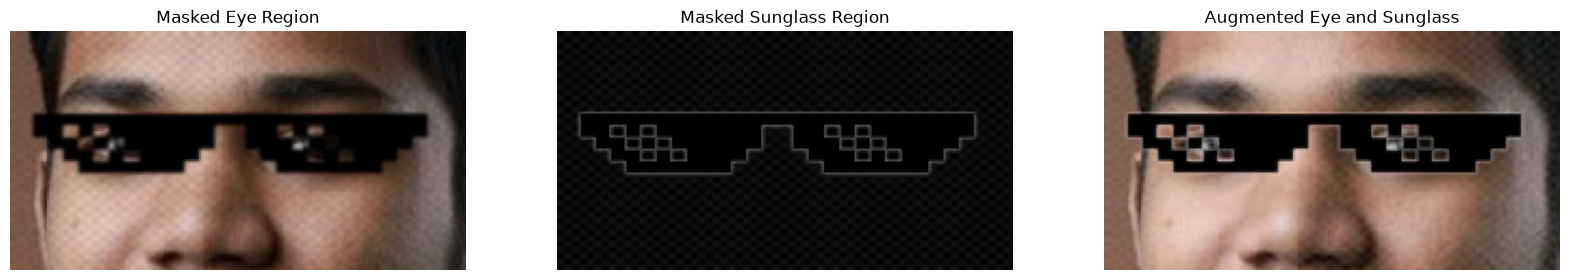

In [15]:
plt.figure(figsize=[20, 8])

plt.subplot(131)
plt.imshow(cv2.cvtColor(maskedEye.astype(np.uint8), cv2.COLOR_BGR2RGB))
plt.title("Masked Eye Region")
plt.axis("off")

plt.subplot(132)
plt.imshow(cv2.cvtColor(maskedGlass.astype(np.uint8), cv2.COLOR_BGR2RGB))
plt.title("Masked Sunglass Region")
plt.axis("off")

plt.subplot(133)
plt.imshow(cv2.cvtColor(eyeRoiFinal.astype(np.uint8), cv2.COLOR_BGR2RGB))
plt.title("Augmented Eye and Sunglass")
plt.axis("off")

plt.show()

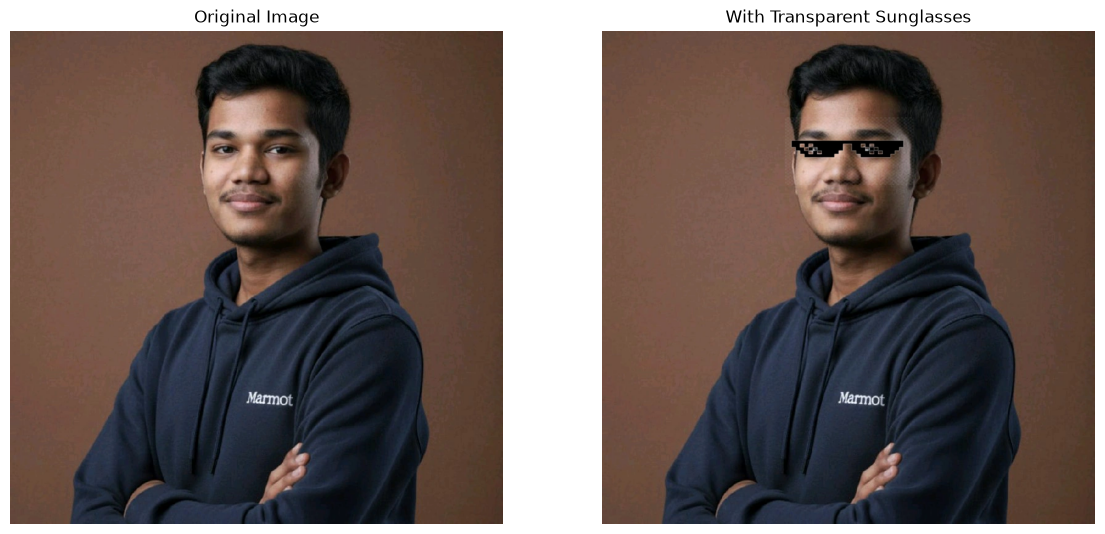

In [16]:
plt.figure(figsize=[14, 7])

plt.subplot(121)
plt.imshow(cv2.cvtColor(faceImage, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")

plt.subplot(122)
plt.imshow(cv2.cvtColor(faceWithGlassesArithmetic, cv2.COLOR_BGR2RGB))
plt.title("With Transparent Sunglasses")
plt.axis("off")

plt.show()